# Use the System Catalog

Pre-phase A studies often ask what a proposed system adds to the *programs of record*: the satellites, radars, and surface stations that already observe. The `tatc.catalog` module holds such baseline systems, so that an analysis can build them rather than assembling orbits and station lists by hand:

* **Satellite systems** (such as JPSS, Metop, and the GOES-R Series) give *idealized orbits*, which do not age as element sets do. At the `plane` grade, an orbit has the plane of the satellite's orbit (its altitude, inclination, and local time), with the relative phases of a constellation whose operator maintains them (such as the Sentinel-2 satellites) or else phases spaced evenly among the satellites built, for the statistics of revisits and coverage. At the `ground_track` grade, it follows the repeat ground track an operator maintains (or a geostationary longitude), for where, and to about a minute when, passes occur, at any epoch. Satellites carry the instruments of the [instrument catalog](UseInstrumentCatalog.ipynb) that list them.
* **Radar networks** (NEXRAD) and **surface networks** (USCRN, ASOS, and AWOS) give dated tables of their stations, built as `RadarStation`s and `SurfacePlatform`s at their ground elevations above the WGS 84 ellipsoid.

Each system states how well it was tested. Its tier is computed from its results against element sets or station metadata held out from its fit, and the thresholds of the [system standard](../../validation/standard.rst), as for instruments. The [system catalog page](../../validation/systems.rst) lists every result.

First, list the systems with their class, tier, configurations, and number of members (spacecraft or stations).

In [1]:
import pandas as pd
from tatc.catalog import get_system, list_systems

pd.set_option("display.max_colwidth", None)
pd.DataFrame([system.summarize() for system in list_systems()])

,system,name,class,tier,configurations,members,active
0,asos,Automated Surface Observing System,surface_network,partial,stations,939,939
1,awos,Automated Weather Observing System,surface_network,partial,stations,895,895
2,cosmic_2,FORMOSAT-7/COSMIC-2,inclined,nominal,plane,6,5
3,dmsp,Defense Meteorological Satellite Program,sun_synchronous,nominal,plane,1,1
4,earthcare,EarthCARE,sun_synchronous,validated,"plane, ground_track",1,1
5,eos,Earth Observing System,sun_synchronous,partial,plane,3,3
6,gcom_w,Global Change Observation Mission - Water,sun_synchronous,validated,"plane, ground_track",1,1
7,goes,GOES-R Series,geostationary,partial,slot,2,2
8,gpm,Global Precipitation Measurement Core Observatory,inclined,validated,plane,1,1
9,himawari,Himawari,geostationary,nominal,slot,1,1


## Inspect a System

The Joint Polar Satellite System has two configurations: the planes of its satellites' orbits, and the repeat ground track (227 orbits in 16 days) on which NOAA keeps NOAA-20 and NOAA-21, each pinned to an ascending node fitted to its element sets. The `validation` property gives each configuration's results against the standard's gates, with the worst result over the satellites.

In [2]:
jpss = get_system("jpss")
jpss.validation.to_frame()

,configuration,grade,tier,metric,value,limit,passed
0,plane,plane,validated,Mean altitude error (p95),0.1154,≤ 10 km,True
1,plane,plane,validated,Inclination error (p95),0.0680,≤ 0.1 deg,True
2,plane,plane,validated,Local time of ascending node error (p95),9.1946,≤ 10 min,True
3,ground_track,ground_track,partial,Mean altitude error (p95),0.0589,≤ 10 km,True
4,ground_track,ground_track,partial,Inclination error (p95),0.0625,≤ 0.1 deg,True
5,ground_track,ground_track,partial,Local time of ascending node error (p95),2.1331,≤ 10 min,True
6,ground_track,ground_track,partial,Node longitude error (p95),21.4217,≤ 10 km,False
7,ground_track,ground_track,partial,Node time error (p95),82.1715,≤ 60 s,False


NOAA-21's ground track passes its gates, while NOAA-20's departed from its fitted node by more than the gates allow over the held-out weeks, so the `ground_track` configuration is `partial`. The planes of all three satellites (including Suomi NPP, retired) pass. Gaps and limitations state what each configuration does not represent:

In [3]:
for gap in jpss.validation.gaps:
    print(gap)
print()
for text in jpss.configurations["ground_track"].limitations:
    print("-", text)

ground_track: node_longitude_error_p95: 21.4217 fails the limit of 10
ground_track: node_time_error_p95: 82.1715 fails the limit of 60

- Passes follow the maintained ground track to within the band in which it is maintained, and their times drift with the local time of the ascending node within its maintenance (by up to about a minute over months); analyses that need passes to seconds should build orbits from current element sets (by each spacecraft's NORAD catalog number).
- The repeat cycle is of days of Terrestrial Time, so pass times slip from the Earth's rotation by the change of the difference between Terrestrial Time and Universal Time (a few tenths of a second a year).
- Suomi NPP, retired, has only its plane.


## Build a Baseline

Consider a proposed small satellite with a thermal imager in a 10:30 sun-synchronous orbit, which would add morning observations over Oklahoma to those of the baseline: the afternoon VIIRS imagers of JPSS, the NEXRAD radars, and the stations of the U.S. Climate Reference Network (USCRN). Satellites at the ground track grade are built without an epoch; those at the plane grade, and the proposed satellite, at the start of the analysis. `payload` selects the cataloged instruments to carry.

In [4]:
from datetime import datetime, timedelta, timezone

from shapely.geometry import box
from tatc.schemas import PointedInstrument, Satellite, SunSynchronousOrbit

start = datetime(2027, 5, 1, tzinfo=timezone.utc)
times = [start + timedelta(seconds=s) for s in range(0, 2 * 86400, 10)]
region = box(-103.0, 33.6, -94.4, 37.0)  # Oklahoma

baseline = jpss.build("ground_track", payload=["viirs"], time_step=10)
proposed = Satellite(
    name="Proposed",
    orbit=SunSynchronousOrbit(
        altitude=550e3, equator_crossing_time="22:30", epoch=start
    ),
    instruments=[
        PointedInstrument(
            name="Thermal imager",
            cross_track_field_of_view=40,
            along_track_field_of_view=1,
            is_rectangular=True,
            is_swept=True,
        )
    ],
)
radars = get_system("nexrad").build(region=region)
uscrn = get_system("uscrn")
stations = uscrn.build(region=region, radius=10000)
# the stations are named by their WBAN identifiers, and get_member_names
# gives their names
names = uscrn.get_member_names()
print([s.name for s in baseline], [r.name for r in radars])
print([names[s.name] for s in stations])

['NOAA-20', 'NOAA-21'] ['KAMA', 'KFDR', 'KINX', 'KLBB', 'KTLX', 'KVNX']
['Muleshoe 19 S, TX', 'Goodwell 2 E, OK', 'Goodwell 2 SE, OK', 'Stillwater 2 W, OK', 'Stillwater 5 WNW, OK']


Each USCRN station's in-situ instruments are an `InSituInstrument`, whose footprint is a disk of the radius its samples are assumed to represent (here 10 km, given with `radius`; the catalog's assumption is 5 km). Collect the footprints of the satellites over two days and of the stations, then find the overpasses of each station: the coincident footprints of the satellites and the stations' disks (which, collected without times, are static), whose columns are suffixed by the footprint of each pair (`_1` for the satellite's, `_2` for the station's).

In [5]:
from tatc.analysis import collect_footprints, find_coincident_ground_track

footprints = collect_footprints(baseline + [proposed], times, mask=region)
disks = collect_footprints(stations)
overpasses = find_coincident_ground_track(
    pd.concat([footprints, disks], ignore_index=True),
    between=("satellite", "surface_platform"),
)
overpasses = overpasses[overpasses.valid_obs]
# the passes over each station (footprints within 15 minutes), by satellite
overpasses.groupby(["surface_platform_2", "satellite_1"]).time_1.agg(
    lambda t: t.dt.floor("15min").nunique()
).unstack(fill_value=0).rename(index=names).rename_axis(
    index="station", columns="passes in two days"
)

passes in two days,NOAA-20,NOAA-21,Proposed
station,,,
"Muleshoe 19 S, TX",7,4,1
"Goodwell 2 E, OK",7,4,2
"Goodwell 2 SE, OK",7,4,2
"Stillwater 2 W, OK",5,6,0
"Stillwater 5 WNW, OK",5,6,0


The radars observe the air above the stations: find which stations' disks lie within the network's coverage at 1,500 m above the ellipsoid, without terrain blockage (see `tatc.preprocess.compute_terrain_mask_for_station` for each station's mask).

In [6]:
from tatc.analysis import compute_radar_track

coverage = compute_radar_track(radars, elevation=1500).geometry.iloc[0]
pd.DataFrame(
    {
        "station": disks.surface_platform.map(names),
        "within_radar_coverage": disks.geometry.within(coverage),
    }
)

,station,within_radar_coverage
0,"Muleshoe 19 S, TX",False
1,"Goodwell 2 E, OK",False
2,"Goodwell 2 SE, OK",False
3,"Stillwater 2 W, OK",True
4,"Stillwater 5 WNW, OK",True


## Map the Baseline

The radars' coverage, the stations' disks, and the swaths of one morning pass of the proposed satellite and one afternoon pass of NOAA-21:

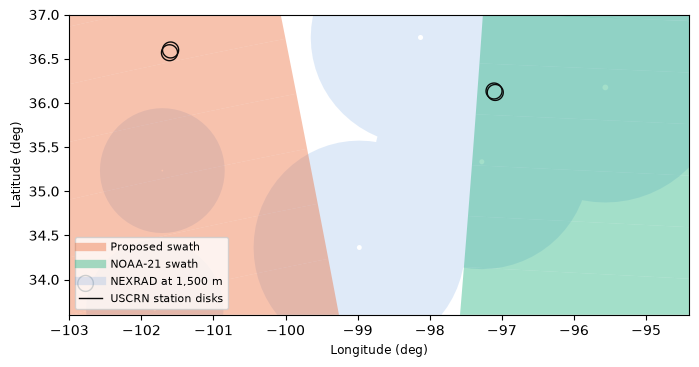

In [7]:
import geopandas as gpd
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
gpd.GeoSeries([coverage.intersection(region)]).plot(
    ax=ax, color="#2a78d6", alpha=0.15, lw=0
)
for name, color in (("Proposed", "#eb6834"), ("NOAA-21", "#1baf7a")):
    swaths = footprints[(footprints.satellite == name) & footprints.valid_obs]
    first = swaths.time.dt.floor("15min").iloc[0]
    swaths[swaths.time.dt.floor("15min") == first].plot(ax=ax, color=color, alpha=0.4, lw=0)
    ax.plot([], [], color=color, lw=6, alpha=0.4, label=f"{name} swath")
disks.boundary.plot(ax=ax, color="#0b0b0b", lw=1)
ax.plot([], [], color="#2a78d6", lw=6, alpha=0.15, label="NEXRAD at 1,500 m")
ax.plot([], [], color="#0b0b0b", lw=1, label="USCRN station disks")
ax.set_xlim(region.bounds[0], region.bounds[2])
ax.set_ylim(region.bounds[1], region.bounds[3])
ax.set_xlabel("Longitude (deg)")
ax.set_ylabel("Latitude (deg)")
ax.legend(loc="lower left", fontsize=8)
plt.show()

## Add an Aircraft

Aircraft and airborne sensors are not cataloged by TAT-C: [HyPlan](https://github.com/ryanpavlick/hyplan) catalogs them (`pip install tatc[airborne]`), and `tatc.preprocess` adapts its models. For a study without a flight plan, `trajectory_from_waypoints` flies a HyPlan aircraft through waypoints at its cruise speed at an altitude above mean sea level (an error above its service ceiling, and a warning beyond its endurance or range), and `aircraft_from_hyplan` builds the aircraft with the instruments of HyPlan's sensors. Here, NASA's P-3 flies HyTES over the stations of central Oklahoma on the proposed satellite's first morning pass.

In [8]:
import hyplan
from tatc.preprocess import aircraft_from_hyplan, trajectory_from_waypoints

pass_time = footprints[footprints.satellite == "Proposed"].time.iloc[0].to_pydatetime()
p3 = hyplan.NASA_P3()
trajectory = trajectory_from_waypoints(
    p3, [(-98.5, 34.8), (-96.5, 36.2)], pass_time - timedelta(minutes=20), 6000
)
aircraft = aircraft_from_hyplan(p3, trajectory, [hyplan.create_sensor("HyTES")])
flight = collect_footprints(aircraft, list(trajectory.time[::10]))
print(aircraft.name, f"{trajectory.ground_speed[0]:.0f} m/s", len(flight), "footprints")

P-3 Orion (NASA 426) 171 m/s 141 footprints
